# Step 17 — after COVID: train on 2005–2018, test on NHANES August 2021 – August 2023

NHANES stopped field work in March 2020 and restarted in August 2021, so there are no NHANES data from during the pandemic. The August 2021 – August 2023 cycle (`_L` files) is the first one after it. This step tests the model trained on 2005–2018 on that cycle.

**2021–2023 cohort:** the same rules as the analysis population (age ≥ 20, not pregnant, all nine PHQ-9 items), built by `pipeline/build_features.ipynb` with `NHANES_COHORT=post2021` into `$NHANES_WORK/features_post2021/`: 5,175 adults, 12.7% with PHQ-9 ≥ 10 (8.9% in 2005–2018).

**Features: 208 of the 317 (`kL`)**, those with all their source variables in the 2021–2023 files and at most 20% missing there. The 2021–2023 questionnaires are shorter: there is no PFQ (physical functioning), BPX (manual blood pressure; BPXO replaces it), CDQ or DUQ, no drug list in RXQ_RX, and many items were dropped from the remaining modules. Among the features lost are several of the strongest: self-rated health `HSD010` (the other self-rated health item, `HUQ010`, remains), trouble sleeping `SLQ050`, all functional limitations, self-rated diet `DBQ700`, the number of prescription drugs and of health-care visits.

Items renamed with the same question and coding are mapped (`RENAME_L` in `build_features`: rooms in home, nightly urination, insurance check-boxes). Marital status has only 3 groups in 2021–2023 (`DMDMARTZ`), so `DMDMARTL` is collapsed to the same 3 groups for training and testing here. The 2021–2023 biochemistry was measured on a Roche Cobas 8000 (an upgrade of the Cobas 6000 used in 2017–18); CDC gives no equation for it, so the 2017–18 equations to the earlier scale are applied to it as well. Remaining shifts against 2017–18 are listed below.

**Design:**
- *Reference within 2005–2018:* leave-one-cycle-out with the same 211 features and inner tuning (`run_loco`), as in steps 1 and 9.
- *After COVID:* elastic net and XGBoost trained on all 7 cycles (hyper-parameters by leave-one-cycle-out over them, as in step 10), tested on 2021–2023. AUROC with a 95% bootstrap interval (1,000 resamples), AUROC weighted with the 2021–2023 MEC weights, AUPRC.
- *Calibration:* Platt scaling fitted on the leave-one-cycle-out predictions (as in step 12) and applied unchanged to 2021–2023, to see whether the rise in prevalence is captured.

**Output:** `$NHANES_WORK/modeling/step17_post_covid/`: `loco_kL/` (the `run_loco` files), `predictions.csv.gz`, `metrics.csv`, `chosen_params.json`. `RUN = True` retrains (about an hour on 6 threads, CPU only); `RUN = False` only reads the saved results.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy.special import expit, logit
from sklearn.metrics import average_precision_score, roc_auc_score

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.loco import FEAT, NOT_FEATURES  # noqa: E402
from nhanes.paths import RESULTS, WORK  # noqa: E402

RUN = False  # True: retrain and overwrite $NHANES_WORK/modeling/step17_post_covid
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
OUT = RESULTS / "step17_post_covid"
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
MARITAL3 = {1: 1, 6: 1, 2: 2, 3: 2, 4: 2, 5: 3}  # married or living with partner / widowed, divorced, separated / never

main = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
post = pd.read_csv(WORK / "features_post2021" / "features_2005_2018.csv.gz")
dic_all = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column")
feats = [c for c in main if c not in NOT_FEATURES]
assert list(post.columns) == list(main.columns)
for d in (main, post):
    d["DMDMARTL"] = d.DMDMARTL.map(MARITAL3)
post["HOD050"] = post.HOD050.where(~post.HOD050.isin([77, 99]))  # refused / don't know of the renamed HOD051

## Which features are available in 2021–2023

In [2]:
RENAMED = {"HOD050", "KIQ480", "DMDMARTL"} | {f"HIQ031{x}" for x in "ABCDFHI"}
CHECK_ALL = {"born_us"}  # derived from alternatives (DMDBORN / DMDBORN2 / DMDBORN4); one is enough


def l_columns():
    import glob
    cols = set()
    for f in glob.glob(str(Path(os.environ.get("NHANES_DATA", ROOT / "data")) / "2021-2023" / "*.xpt")):
        r = pd.read_sas(f, format="xport", encoding="latin1", chunksize=10)
        cols |= set(next(r).columns)
        r.close()
    return cols


present = l_columns()
miss_l = post[feats].isna().mean()
rows = []
for f in feats:
    kind = dic_all.kind[f]
    srcs = [s for s in str(dic_all.sources[f]).replace(",", " ").replace(";", " ").split() if s.isupper() and len(s) > 3]
    absent = sorted(set(s for s in srcs if s not in present) - RENAMED)
    alt_ok = kind == "harmonized" and len(absent) < len(srcs) or f in CHECK_ALL
    reason = ""
    if absent and not alt_ok:
        reason = "source absent in 2021-23: " + " ".join(absent)
    elif miss_l[f] > 0.20:
        reason = f"missing {miss_l[f]:.0%} in 2021-23"
    rows.append({"feature": f, "kind": kind, "missing_2021_23": miss_l[f], "excluded": reason})
avail = pd.DataFrame(rows)
KL = avail.feature[avail.excluded == ""].tolist()
print(f"{len(KL)} of {len(feats)} features kept (kL)")
display(avail[avail.excluded != ""].assign(why=avail.excluded.str.split(":").str[0])
        .groupby("why").size().rename("features excluded"))
STRONG = ["HSD010", "HUQ010", "SLQ050", "PFQ049", "PFQ051", "pf_difficulty_count", "DBQ700", "INDFMPIR",
          "sleep_hours", "rx_count", "healthcare_visits"]
display(avail.set_index("feature").loc[STRONG, ["missing_2021_23", "excluded"]].round(3))

208 of 317 features kept (kL)


why
missing 100% in 2021-23       5
missing 25% in 2021-23        1
missing 33% in 2021-23        1
missing 86% in 2021-23        1
missing 89% in 2021-23        1
source absent in 2021-23    100
Name: features excluded, dtype: int64

,missing_2021_23,excluded
feature,,
HSD010,1.00,source absent in 2021-23: HSD010
HUQ010,0.00,
SLQ050,1.00,source absent in 2021-23: SLQ050
PFQ049,1.00,source absent in 2021-23: PFQ049
PFQ051,1.00,source absent in 2021-23: PFQ051
pf_difficulty_count,1.00,source absent in 2021-23: PFQ049-059 PFQ061A-T
DBQ700,1.00,source absent in 2021-23: DBQ700
INDFMPIR,0.12,
sleep_hours,0.01,


Shift of the kept features between 2017–18 and 2021–23: standardised mean difference, largest 15. Large values in the biochemistry (bicarbonate, sodium, calcium, osmolality) follow the change of analyser; education, household size and income reflect a different sample (the 2021–2023 response rates were lower).

In [3]:
r17 = main[main.cycle == "2017-18"]
shift = []
for f in KL:
    x, y = r17[f].replace(-1, np.nan).dropna(), post[f].replace(-1, np.nan).dropna()
    sd = np.sqrt((x.var() + y.var()) / 2)
    shift.append({"feature": f, "kind": dic_all.kind[f], "SMD 2021-23 vs 2017-18": (y.mean() - x.mean()) / sd if sd else 0,
                  "meaning": str(dic_all.rule[f])[:60]})
shift = pd.DataFrame(shift)
display(shift.reindex(shift["SMD 2021-23 vs 2017-18"].abs().sort_values(ascending=False).index).head(15)
        .set_index("feature").round(2))
avail.to_csv(OUT / "feature_availability.csv", index=False) if OUT.exists() else None

,kind,SMD 2021-23 vs 2017-18,meaning
feature,,,
DR_TP204,diet_mean,-0.51,PFA 20:4 (Eicosatetraenoic) (gm) (mean of both...
LBXSC3SI,raw,-0.46,Bicarbonate (mmol/L)
DMDHHSIZ,raw,-0.42,Total number of people in the Household
LBXSNASI,raw,-0.35,Sodium (mmol/L)
DMDEDUC2,raw,0.33,Education level - Adults 20+
LBXSCA,raw,0.33,Total Calcium (mg/dL)
binge_freq,harmonized,0.31,"days with heavy drinking, ALQ121 scale; NOTE 2..."
LBXSOSSI,raw,-0.30,Osmolality (mmol/Kg); 2017-18 recalculated as ...
born_us,derived,0.28,1 born in 50 states or DC (code 1 in all versi...


## Run

In [4]:
if RUN:
    from nhanes.loco import LOGREG_GRID, XGB_GRID, fit_logreg, fit_xgb, grid, logreg_matrix, run_loco, tune

    OUT.mkdir(parents=True, exist_ok=True)
    avail.to_csv(OUT / "feature_availability.csv", index=False)
    dic = dic_all.type.to_dict()
    run_loco(main[NOT_FEATURES + KL], dic, OUT / "loco_kL", title="leave-one-cycle-out, kL features (available in 2021-23)")
    cycles = sorted(main.cycle.unique())
    preds, chosen = [], {}
    for model, g in [("logreg", LOGREG_GRID), ("xgboost", XGB_GRID)]:
        params, inner = tune(model, main[NOT_FEATURES + KL], cycles, dic, grid(g))
        if model == "logreg":
            A, B = logreg_matrix(main[KL], post[KL], dic)
            prob = fit_logreg(A, main.depression, params).predict_proba(B)[:, 1]
        else:
            fit_p = {k: v for k, v in params.items() if k != "n_estimators"}
            prob = fit_xgb(main[KL], main.depression, None, None, fit_p,
                           n_estimators=params["n_estimators"]).predict_proba(post[KL])[:, 1]
        chosen[model] = {**params, "inner_auroc": round(inner, 4)}
        preds.append(pd.DataFrame({"SEQN": post.SEQN, "model": model, "depression": post.depression,
                                   "weight": post.WTMEC2YR, "prob": prob}))
        print(model, chosen[model], flush=True)
    pd.concat(preds, ignore_index=True).to_csv(OUT / "predictions.csv.gz", index=False)
    (OUT / "chosen_params.json").write_text(json.dumps(chosen, indent=1))

## Results: discrimination

In [5]:
pred = pd.read_csv(OUT / "predictions.csv.gz")
loco = pd.read_csv(OUT / "loco_kL" / "metrics.csv")
full = pd.read_csv(RESULTS / "step1" / "metrics.csv")
rng = np.random.default_rng(42)
rows = []
for model in NAMES:
    g = pred[pred.model == model]
    y, p = g.depression.to_numpy(), g.prob.to_numpy()
    boot = []
    while len(boot) < 1000:
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            boot.append(roc_auc_score(y[i], p[i]))
    lo = loco[loco.model == model].set_index("test_cycle").auroc
    rows.append({"model": NAMES[model],
                 "317 features, LOCO 2005-18 (step 1)": full[full.model == model].auroc.mean(),
                 "kL, LOCO 2005-18": lo.mean(), "kL, LOCO: 2017-18": lo["2017-18"],
                 "kL, trained 2005-18 → 2021-23": roc_auc_score(y, p),
                 "95% CI": f"{np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f}",
                 "2021-23 weighted": roc_auc_score(y, p, sample_weight=g.weight),
                 "2021-23 AUPRC": average_precision_score(y, p), "2021-23 rate": y.mean()})
met = pd.DataFrame(rows).set_index("model")
display(met.round(3))
for model in NAMES:
    d = met.loc[NAMES[model]]
    print(f"{NAMES[model]}: 2021-23 minus LOCO mean {d['kL, trained 2005-18 → 2021-23'] - d['kL, LOCO 2005-18']:+.3f}; "
          f"minus 2017-18 {d['kL, trained 2005-18 → 2021-23'] - d['kL, LOCO: 2017-18']:+.3f}; "
          f"cost of the feature cut (kL vs 317, LOCO) {d['kL, LOCO 2005-18'] - d['317 features, LOCO 2005-18 (step 1)']:+.3f}")
print("kL LOCO per cycle:")
display(loco.pivot(index="test_cycle", columns="model", values="auroc").rename(columns=NAMES).round(3))

,"317 features, LOCO 2005-18 (step 1)","kL, LOCO 2005-18","kL, LOCO: 2017-18","kL, trained 2005-18 → 2021-23",95% CI,2021-23 weighted,2021-23 AUPRC,2021-23 rate
model,,,,,,,,
elastic net,0.874,0.836,0.803,0.801,0.784–0.819,0.782,0.383,0.127
XGBoost,0.871,0.836,0.802,0.799,0.782–0.815,0.778,0.373,0.127


elastic net: 2021-23 minus LOCO mean -0.035; minus 2017-18 -0.002; cost of the feature cut (kL vs 317, LOCO) -0.038
XGBoost: 2021-23 minus LOCO mean -0.037; minus 2017-18 -0.002; cost of the feature cut (kL vs 317, LOCO) -0.035
kL LOCO per cycle:


model,elastic net,XGBoost
test_cycle,,
2005-06,0.855,0.852
2007-08,0.849,0.849
2009-10,0.826,0.829
2011-12,0.838,0.841
2013-14,0.840,0.838
2015-16,0.840,0.842
2017-18,0.803,0.802


## Calibration: does the model see the rise in prevalence?

Platt scaling fitted on the leave-one-cycle-out predictions of 2005–2018 (kL), applied unchanged to 2021–2023. If the calibrated mean prediction stays near the 2005–2018 rate while the observed rate is 12.7%, the rise is not explained by the features.

In [6]:
loco_pred = pd.read_csv(OUT / "loco_kL" / "predictions.csv.gz")
rows = []
cal_frames = []
for model in NAMES:
    h = loco_pred[loco_pred.model == model]
    z = logit(h.prob.clip(1e-6, 1 - 1e-6))
    a, b = sm.GLM(h.depression, sm.add_constant(z), family=sm.families.Binomial()).fit().params
    g = pred[pred.model == model].copy()
    g["cal"] = expit(a + b * logit(g.prob.clip(1e-6, 1 - 1e-6)))
    zc = logit(g.cal.clip(1e-6, 1 - 1e-6))
    icpt = sm.GLM(g.depression, np.ones((len(g), 1)), family=sm.families.Binomial(), offset=zc).fit().params[0]
    slope = sm.GLM(g.depression, sm.add_constant(zc), family=sm.families.Binomial()).fit().params.iloc[1]
    rows.append({"model": NAMES[model], "2005-18 rate": h.depression.mean(),
                 "2021-23 observed": g.depression.mean(), "2021-23 mean predicted (calibrated)": g.cal.mean(),
                 "calibration intercept": icpt, "calibration slope": slope,
                 "weighted observed": np.average(g.depression, weights=g.weight),
                 "weighted mean predicted": np.average(g.cal, weights=g.weight)})
    cal_frames.append(g.assign(model=NAMES[model]))
cal = pd.DataFrame(rows).set_index("model")
display(cal.round(3))
pd.concat([met, cal], axis=1).to_csv(OUT / "metrics.csv")

,2005-18 rate,2021-23 observed,2021-23 mean predicted (calibrated),calibration intercept,calibration slope,weighted observed,weighted mean predicted
model,,,,,,,
elastic net,0.089,0.127,0.092,0.454,0.854,0.122,0.083
XGBoost,0.089,0.127,0.089,0.503,0.833,0.122,0.080


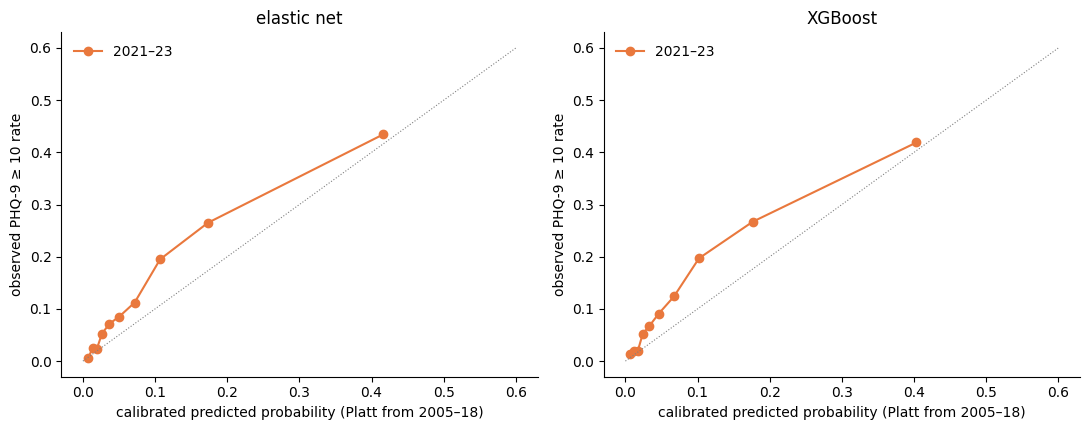

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, g in zip(axes, cal_frames):
    q = pd.qcut(g.cal, 10, duplicates="drop")
    b = g.groupby(q, observed=True).agg(pred=("cal", "mean"), obs=("depression", "mean"))
    ax.plot(b.pred, b.obs, "o-", color="#E9783D", label="2021–23")
    ax.plot([0, 0.6], [0, 0.6], color="grey", lw=0.8, ls=":")
    ax.set_xlabel("calibrated predicted probability (Platt from 2005–18)")
    ax.set_ylabel("observed PHQ-9 ≥ 10 rate")
    ax.set_title(g.model.iloc[0])
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plots.show()

## Conclusions

- **Discrimination after COVID is the same as in the last cycle before it.** Trained on 2005–2018 and tested on 2021–2023, AUROC is 0.801 (95% CI 0.784–0.819) for elastic net and 0.799 (0.782–0.815) for XGBoost. With the same 208 features, the most recent pre-pandemic cycle, 2017–18, reached 0.803 / 0.802 in leave-one-cycle-out. So there is no further drop after the pandemic beyond what 2017–18 already shows.
- **Against the 2005–2018 average it is 0.035 lower** (leave-one-cycle-out mean 0.836). The drop is a trend over time rather than a step at COVID: the cycles 2005–06 to 2015–16 are at 0.826–0.855, and 2017–18 already falls to 0.803. With only one cycle after the pandemic, a COVID effect cannot be separated from that trend.
- **The 2021–2023 questionnaire costs more than the pandemic.** Restricting to the 208 features available there lowers leave-one-cycle-out AUROC from 0.874 / 0.871 to 0.836 / 0.836 (−0.038 / −0.035): self-rated health `HSD010`, trouble sleeping, functional limitations, self-rated diet, the number of prescription drugs and of health-care visits are no longer asked in that form.
- **The rise in depression is not explained by the features.** PHQ-9 ≥ 10 rose from 8.9% (2005–2018) to 12.7% (12.2% weighted) in 2021–2023. Calibrated on 2005–2018, the model predicts 9.2% / 8.9% on average for 2021–2023: calibration intercept +0.45 / +0.50, i.e. the odds of depression are about 1.6 times what the measured characteristics of the people predict. The rise therefore comes from something not captured by these features (the pandemic period itself is one candidate), not from a change in the population's measured profile. The calibration slope is 0.85 / 0.83 (predictions slightly too spread).
- **Weighted AUROC is lower (0.782 / 0.778)** than unweighted, as in the earlier cycles where the weighted value differs by a few hundredths.
- **Limits:** one post-pandemic cycle only, with lower response rates and a smaller sample (5,175 adults) than before; the biochemistry was measured on a new analyser (electrolytes shift by 0.3–0.5 SD against 2017–18); and there are no NHANES data from during the pandemic.